# Task 3 - Malicious URL classification

Zhanna Azatkyzy, Dariyana Gabdylshukir

This notebook loads the complete recorded raw log, removes warm-up, recomputes statistics and exports publication figures. It does not train models or repeat timing. The positive label is malicious, not phishing-specific.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
from IPython.display import display, Image
root=Path.cwd() if (Path.cwd()/'src').exists() else Path.cwd().parent
sys.path.insert(0,str(root/'src'))
import process_data as pr
import visualize as vis
np.random.seed(42)
run=root/'data/review_runs/20261105T122952Z_dbea27e6'
print('Recorded run:',run.name)
print('Bootstrap seed: 42; 2,000 resamples')

Recorded run: 20261105T122952Z_dbea27e6
Bootstrap seed: 42; 2,000 resamples


## 1. Data ingestion and warm-up filtering

The full gzip-compressed JSONL is the analysis input. The small `data/raw/test_run.jsonl` is illustrative only. Twenty calls per configuration, repeat and rate are marked as warm-up. Exclusion follows the recorded phase; it is not based on discarding inconvenient slow observations.

In [2]:
meta, raw_quality, calls=pr.load_raw(run)
evaluation=pr.remove_warmup(calls)
print('Quality records:',len(raw_quality))
print('All request records:',len(calls))
print('Warm-up removed:',len(calls)-len(evaluation))
print('Evaluation calls:',len(evaluation))
assert len(raw_quality)==80 and len(evaluation)==240000
display(calls[['model','feature_set','repeat','phase','target_rps','latency_ms']].head())

Quality records: 80
All request records: 244800
Warm-up removed: 4800
Evaluation calls: 240000


,model,feature_set,repeat,phase,target_rps,latency_ms
0,xgboost,full,1,warmup,50.0,3.7624
1,xgboost,full,1,warmup,50.0,1.8980
2,xgboost,full,1,warmup,50.0,3.6704
3,xgboost,full,1,warmup,50.0,1.5695
4,xgboost,full,1,warmup,50.0,1.2952


### Domain split checks

Thirty percent of registrable-domain groups are held out; URL proportions vary. Groups include private public-suffix boundaries. Each repeat has disjoint training/test domains, although repeats share observations.

In [3]:
df=pd.read_csv(run/'cleaned_dataset.csv')
checks=[]
for path in sorted(run.glob('split_*.npz')):
    split=np.load(path);tr,te=split['train'],split['test']
    assert not set(tr)&set(te)
    assert len(set(tr)|set(te))==len(df)
    overlap=len(set(df.iloc[tr].domain)&set(df.iloc[te].domain))
    assert overlap==0
    checks.append({'split':path.stem,'train':len(tr),'test':len(te),'shared_domains':overlap})
assert len(checks)==10
display(pd.DataFrame(checks))

,split,train,test,shared_domains
0,split_01,13845,6134,0
1,split_02,14281,5698,0
2,split_03,13252,6727,0
3,split_04,13429,6550,0
4,split_05,14531,5448,0
5,split_06,14281,5698,0
6,split_07,13189,6790,0
7,split_08,13298,6681,0
8,split_09,13487,6492,0
9,split_10,14095,5884,0


## 2. Statistical aggregation

`aggregate` computes metrics from confusion counts, repeat-level p50/p95/p99, error rates and 95% bootstrap intervals. It uses the fixed seed in metadata. Latency summaries are means of repeat percentiles, not pooled percentiles. Confidence intervals describe conditional variability, not independent-dataset inference or a formal significance test.

In [4]:
tables=pr.aggregate(meta,raw_quality,evaluation)
quality=tables['quality_summary']
display(quality[['model','feature_set','f1_mean','f1_sd','f1_ci_low','f1_ci_high','recall_mean']].round(4))

,model,feature_set,f1_mean,f1_sd,f1_ci_low,f1_ci_high,recall_mean
0,logistic_regression,full,0.3238,0.0276,0.3080,0.3397,0.2002
1,logistic_regression,selected,0.2135,0.0195,0.2016,0.2251,0.1217
2,random_forest,full,0.5902,0.0199,0.5778,0.6015,0.5545
3,random_forest,selected,0.3673,0.0150,0.3589,0.3767,0.2962
4,svm,full,0.3933,0.0287,0.3755,0.4101,0.2551
5,svm,selected,0.2762,0.0235,0.2637,0.2917,0.1652
6,xgboost,full,0.6023,0.0178,0.5919,0.6129,0.5117
7,xgboost,selected,0.3699,0.0184,0.3598,0.3814,0.2539


In [5]:
guard=tables['guardrails']
display(guard[['model','feature_set','target_rps','p50_ms','p95_ms','p99_ms','worst_repeat_p99_ms','total_errors','recall_ok','latency_ok','passed']].round(3))
summary=pr.export_tables(tables,root/'data/processed')
print('Exported:',len(summary),'benchmark rows to data/processed/metrics_summary.csv')

,model,feature_set,target_rps,p50_ms,p95_ms,p99_ms,worst_repeat_p99_ms,total_errors,recall_ok,latency_ok,passed
0,logistic_regression,full,50.0,1.918,3.831,18.640,20.191,0,False,True,False
1,logistic_regression,full,200.0,1.458,2.594,16.468,22.689,0,False,True,False
2,logistic_regression,full,500.0,0.901,2.520,15.813,26.446,0,False,True,False
3,logistic_regression,selected,50.0,1.891,3.406,17.408,19.057,0,False,True,False
4,logistic_regression,selected,200.0,1.455,2.749,17.563,22.790,0,False,True,False
5,logistic_regression,selected,500.0,0.912,2.613,16.527,25.596,0,False,True,False
6,random_forest,full,50.0,6.017,9.022,21.259,25.279,0,False,True,False
7,random_forest,full,200.0,4.354,5.068,12.996,22.408,0,False,True,False
8,random_forest,full,500.0,1066.169,2150.111,2265.842,2306.906,0,False,False,False
9,random_forest,selected,50.0,5.934,8.922,19.430,23.121,0,False,True,False


Exported: 24 benchmark rows to data/processed/metrics_summary.csv


## 3. Visualization and export

Colorblind-safe colors, distinct line styles/markers, physical axis units and logarithmic latency axes are used. Figure 1 shows bootstrap intervals for mean repeat percentiles. In Figure 2, black diamonds and vertical intervals show mean F1 and mean repeat p50 with 95% bootstrap CI. The latency boxplots show request dispersion at 50 RPS. Every figure is exported as vector PDF and 300 DPI PNG.

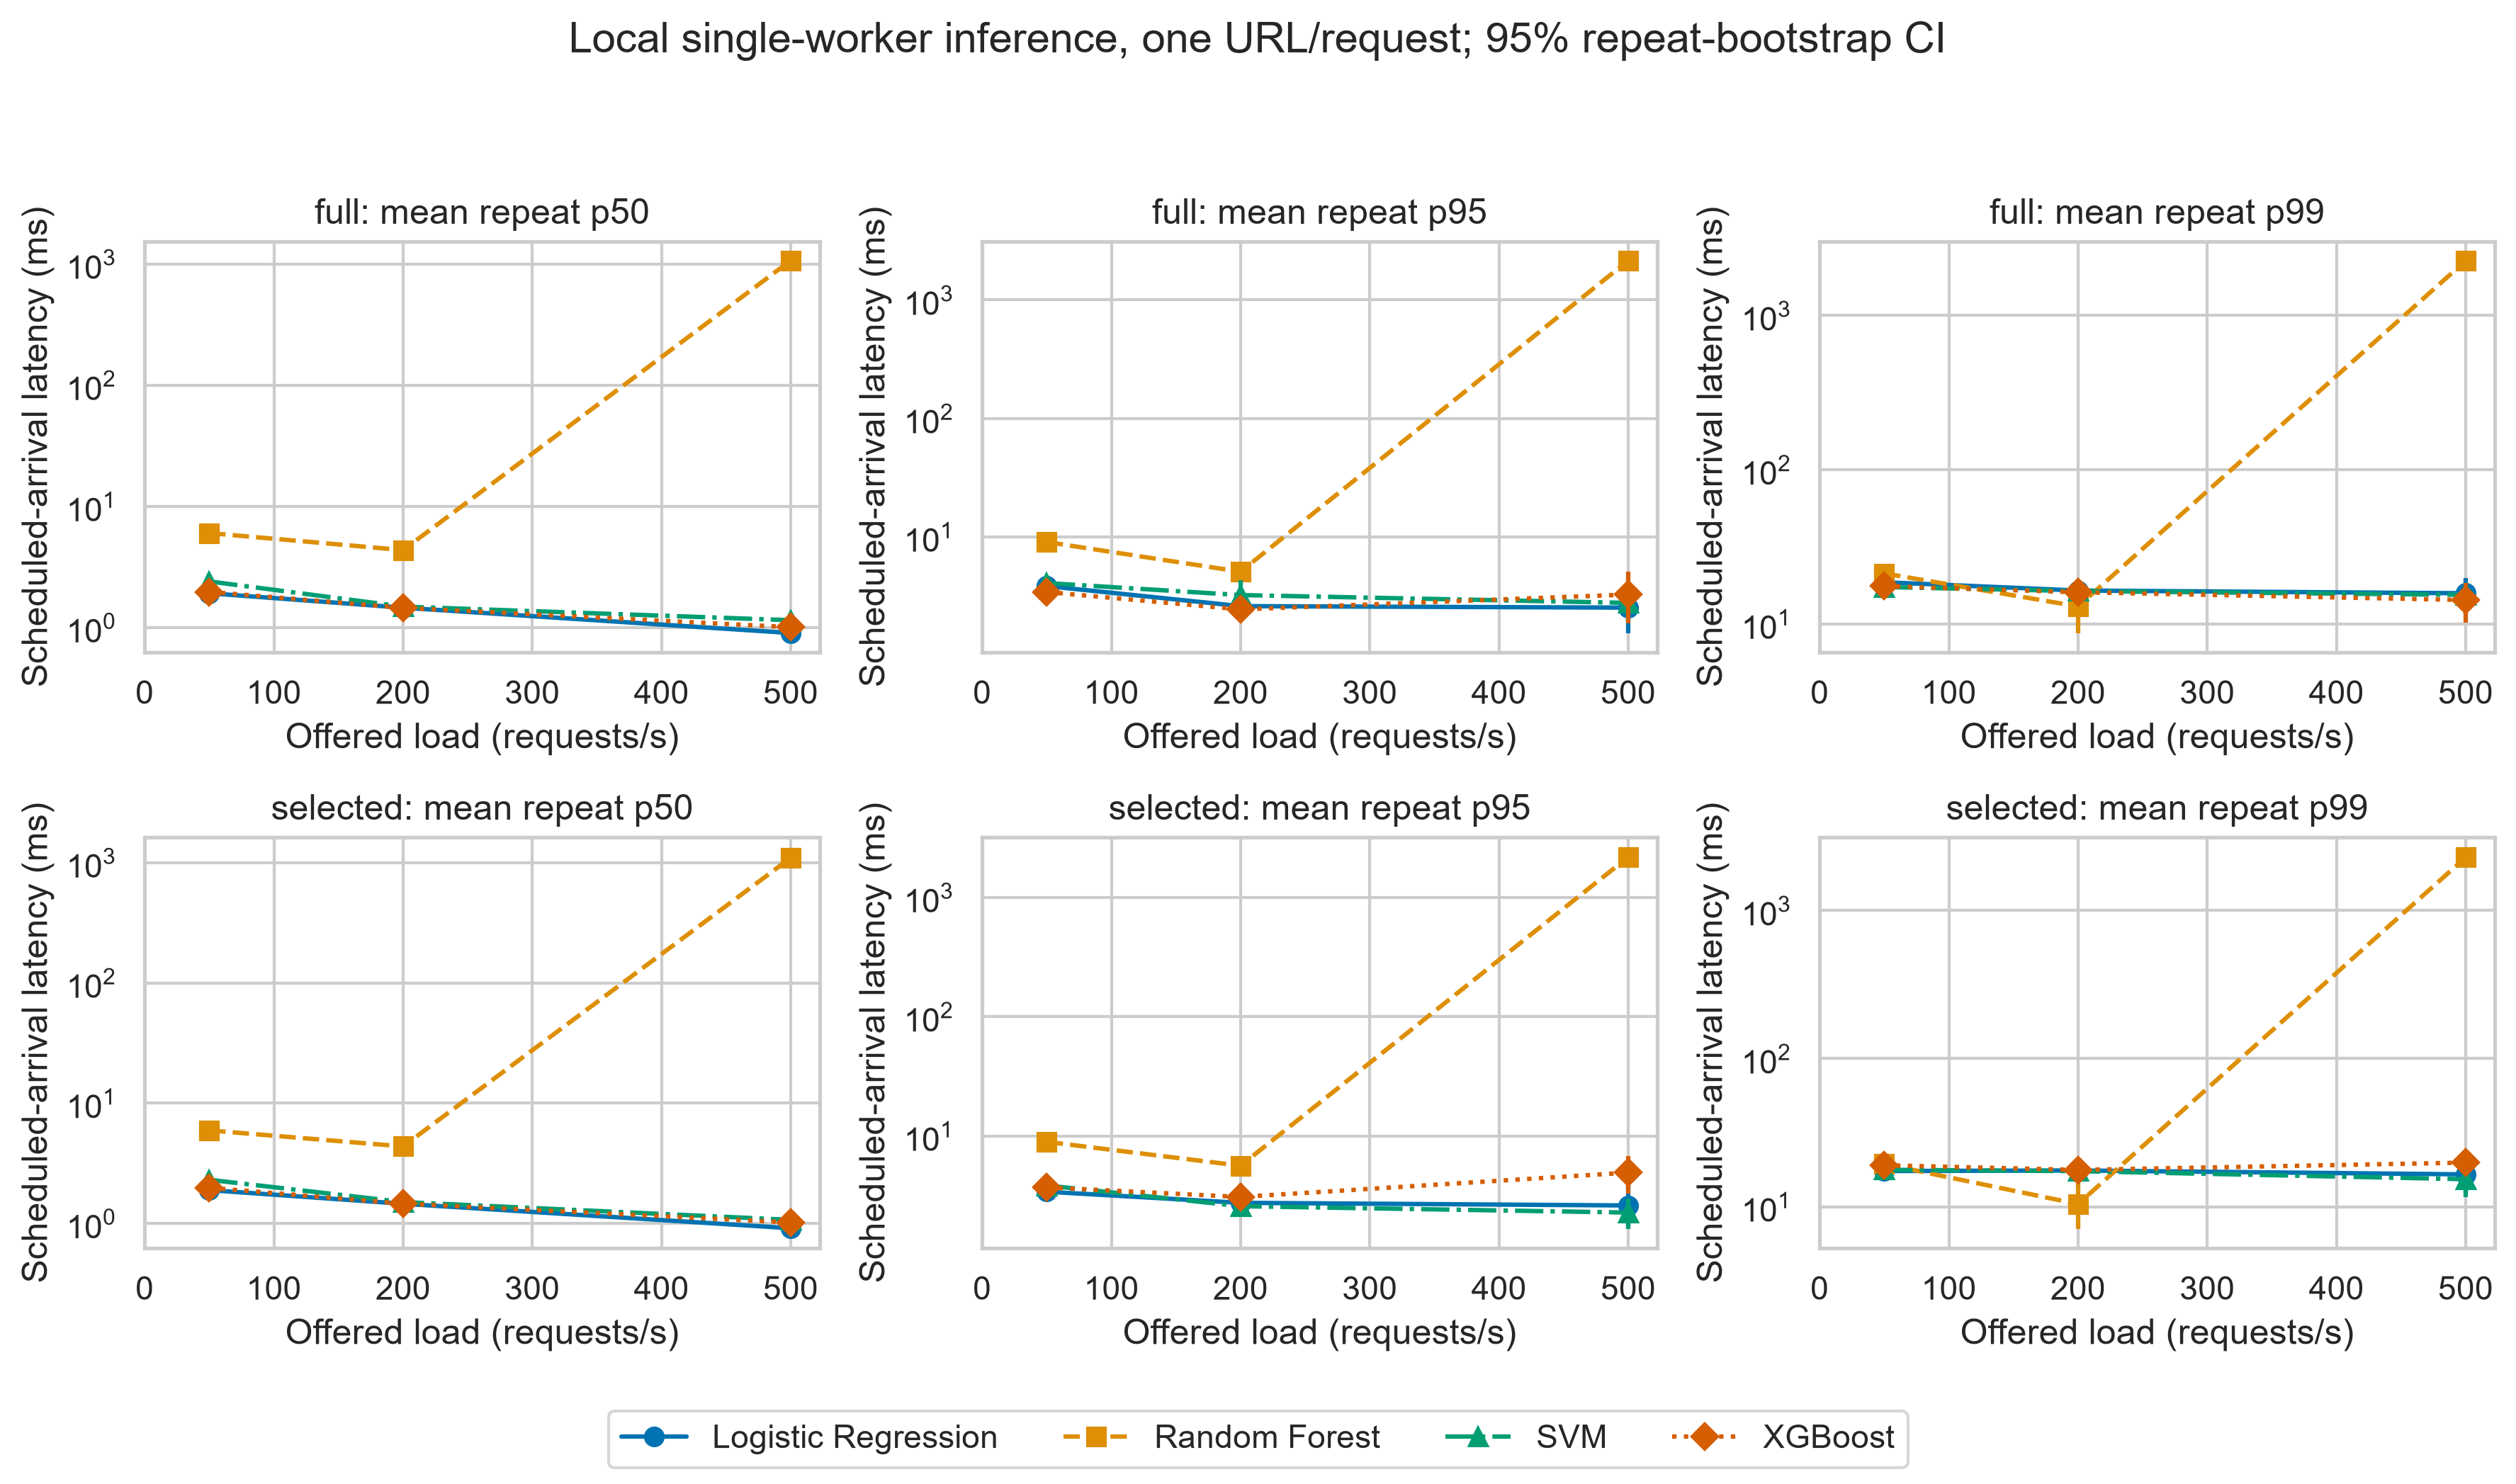

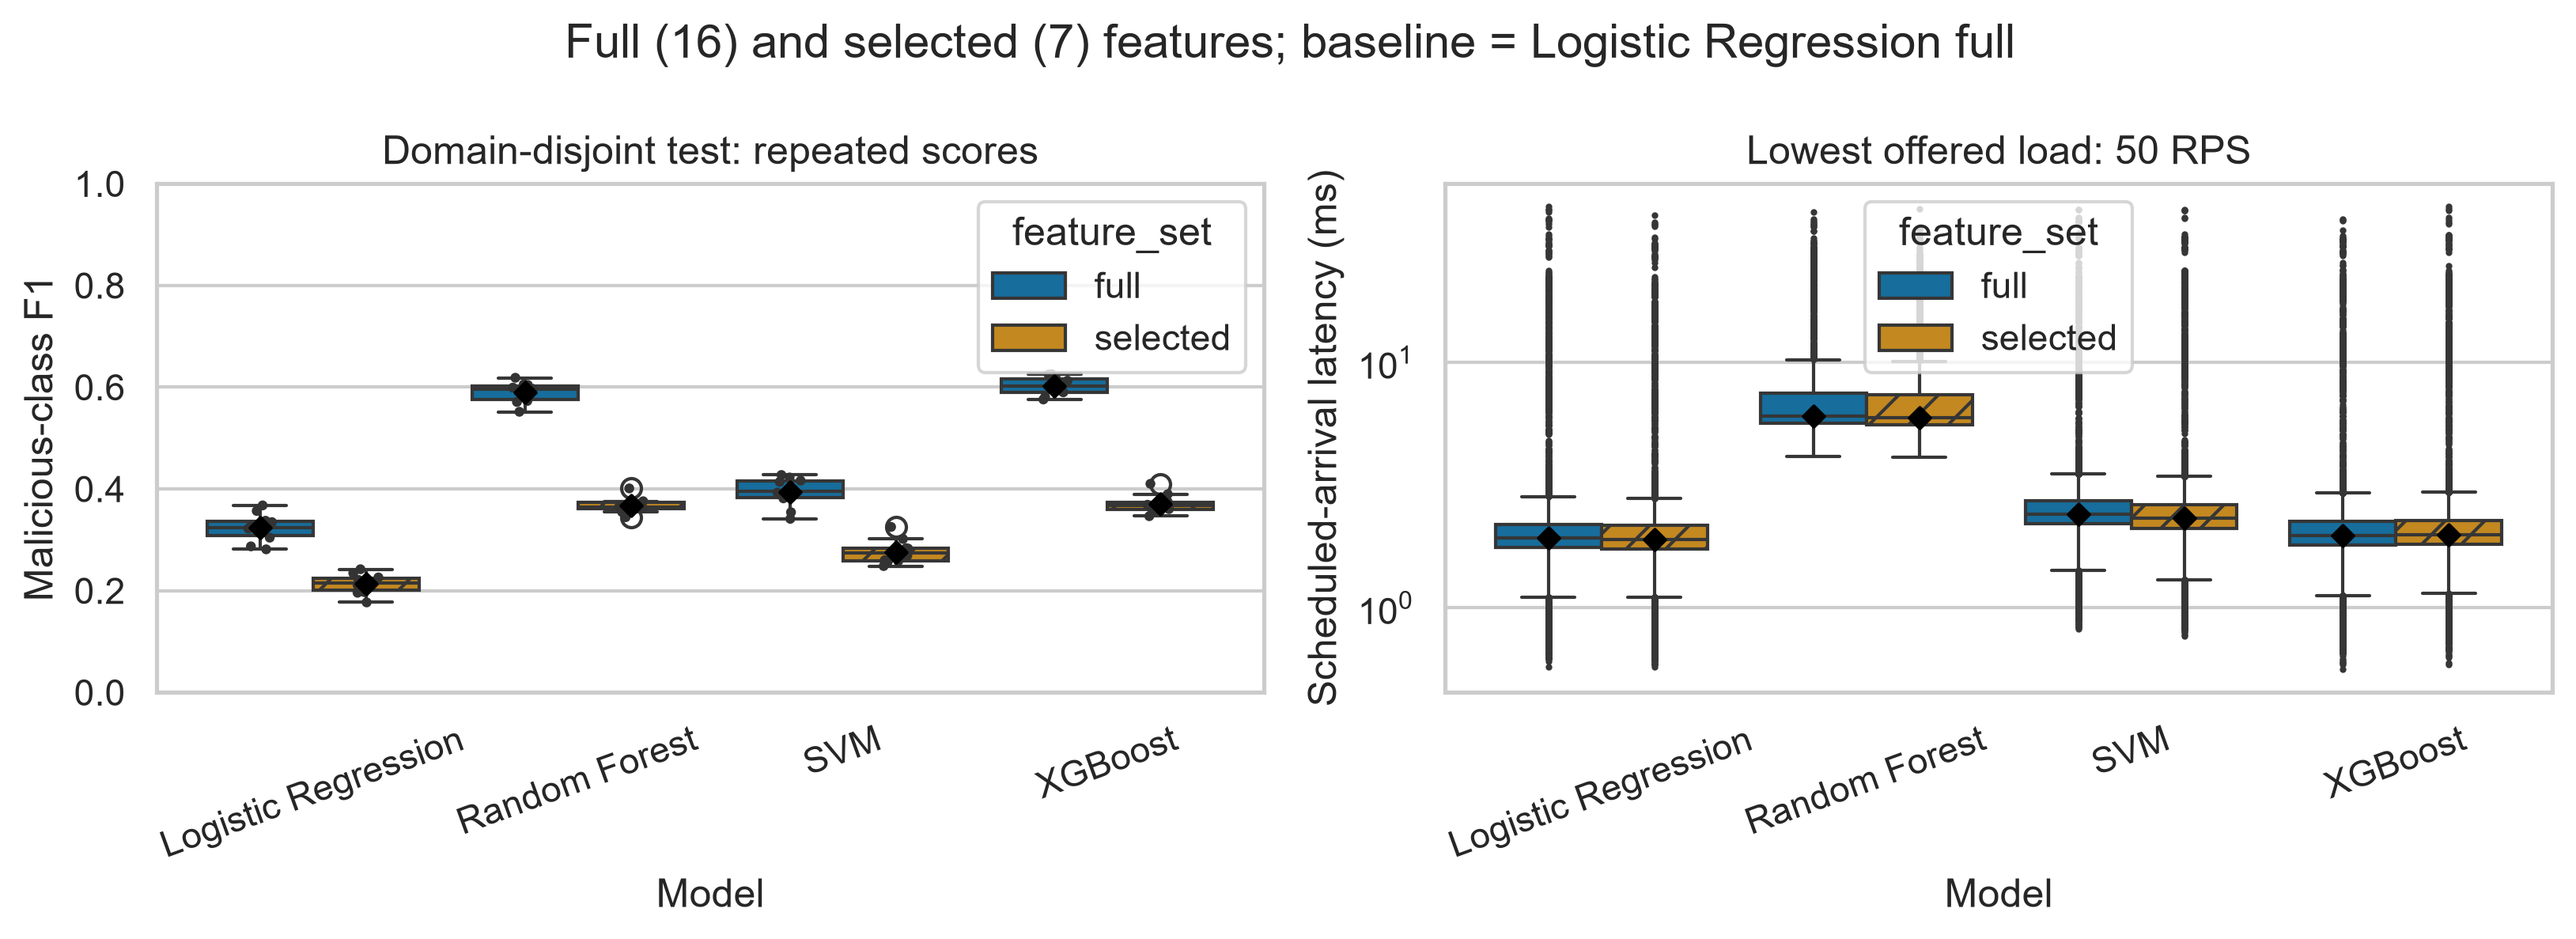

Saved two PDF and two PNG figures.


In [6]:
assets=vis.plot_results(meta,tables,evaluation,root/'reports/figures')
for path in assets:
    display(Image(filename=str(path)))
print('Saved two PDF and two PNG figures.')

## 4. Conclusions

XGBoost full has the highest observed mean F1 (0.602); Random Forest full has the highest mean recall (0.555). All four models lose F1 with seven features. No model meets recall 0.80. There are zero recorded execution errors. Random Forest fails the 100 ms worst-repeat p99 threshold at 500 RPS because a queue develops in these finite trials; other configurations meet the latency threshold. No formal significance claim is made.

The labels are malicious/benign, not phishing-specific. Full lexical extraction precedes selecting seven features, so this is not a benchmark of an optimized seven-feature extractor. Timing includes scheduler lag, queueing and service time in one local worker, without HTTP/network overhead. Results apply to the recorded environment and finite workload.